# Content

Tests the analysis pipeline

# Imports

In [5]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix
import seaborn as sns
import os
import sklearn
import time
import random
from datetime import datetime

from helpers import *
from helpers_analysis import * 
from implementations import * 

# Useful functions

In [6]:
#Functions logistic regression SGD

def logistic_regression_sgd(y_tr, tx_tr, y_te, tx_te, initial_w, max_iters, gamma):
    """Implementation of logistic regression.

    Args:
        y:  shape=(N, 1)
        tx: shape=(N, D)
        initial_w:  shape=(D, 1)
        max_iters: scalar denoting the total number of iterations
        gamma: scalar denoting the stepsize


    Returns:
        w: numpy array of shape=(D, ) denoting the final model parameters
        loss: scalar denoting final loss value
    """

    w = initial_w
    N = len(y_tr)
    losses_train = []
    losses_test = []
    for n_iter in range(max_iters):

        #Index random choice and update
        idx = np.random.randint(N)
        grad = tx_tr[idx].T*(1/(1+np.exp(-tx_tr[idx]*w)) - y_tr[idx])/N
        w = w - gamma * grad

        #Loss computations
        loss_train = np.mean(-y_tr*(tx_tr@w) + np.log(1 + np.exp(tx_tr@w)))
        losses_train.append(loss_train)
        loss_test = np.mean(-y_te*(tx_te@w) + np.log(1 + np.exp(tx_te@w)))
        losses_test.append(loss_test)
    
    return w, losses_train, losses_test

def reg_logistic_regression_sgd(y_tr, tx_tr, y_te, tx_te, lambda_, initial_w, max_iters, gamma):
    """Implementation of logistic regression.

    Args:
        y:  shape=(N, 1)
        tx: shape=(N, D)
        initial_w:  shape=(D, 1)
        max_iters: scalar denoting the total number of iterations
        gamma: scalar denoting the stepsize


    Returns:
        w: numpy array of shape=(D, ) denoting the final model parameters
        loss: scalar denoting final loss value
    """

    w = initial_w
    N = len(y_tr)
    losses_train = []
    losses_test = []
    for n_iter in range(max_iters):
        idx = np.random.randint(N)
        grad = tx_tr[idx].T*(1/(1+np.exp(-tx_tr[idx]*w)) - y_tr[idx])/N + 2 * lambda_ * w 
        w = w - gamma * grad

        #Loss computations
        loss_train = np.mean(-y_tr*(tx_tr@w) + np.log(1 + np.exp(tx_tr@w)))
        losses_train.append(loss_train)
        loss_test = np.mean(-y_te*(tx_te@w) + np.log(1 + np.exp(tx_te@w)))
        losses_test.append(loss_test)

    loss = np.mean(-y_tr*(tx_tr@w) + np.log(1 + np.exp(tx_tr@w)))
    
    return w, losses_train, losses_test

In [7]:
#Functions display

def display_losses(losses_train, losses_test, title) :
    #Loss display: pure logistic
    plt.plot(losses_train, label="Train")
    plt.plot(losses_test, label="Test")
    plt.ylabel("Loss value")
    plt.xlabel("Iteration")
    plt.title(f"Loss value during optimization, {title}")
    plt.legend(loc="upper right")
    plt.savefig(f"image/losses_{title}.png", dpi=300)
    plt.show()

In [8]:
#Functions confusion matrix

def confusion_matrix_custom(y_te, y_te_pred) :
    """Computes the confusion matrix (cm_custom) between true labels (y_te) and predicted labels (y_te_pred)"""
    cm_custom = np.zeros((2,2))

    for i,elt in enumerate(y_te_pred) :
        #Class 0 which is true (True negative)
        if elt == 0 and elt == y_te[i] :
            cm_custom[1,1] += 1

        #Class 0 which is false (under-estimated ==> death) (false negative)
        elif elt == 0 and elt != y_te[i] :
            cm_custom[0, 1] += 1

        #Class 1 which is false (over-prediction) (false positive)
        elif elt == 1 and elt != y_te[i] :
            cm_custom[1, 0] += 1
            
        #Class 1 which is true (True negative)
        elif elt == 1 and elt == y_te[i] :
            cm_custom[0, 0] += 1

    cm_ratio_custom = cm_custom/len(y_te)

    return(cm_custom, cm_ratio_custom)

def display_confusion_matrix(cm, cm_ratio, title) :
    """Display confusion matrix only with matplotlib. Convention: positive when class 1 (ie heart disease)"""
    
    L_labels = [["True Positive", "False Negative"], ["False Positive", "False positive"]]

    #Figure creation
    fig, ax = plt.subplots(1, 2, figsize=(12, 5))

    #Heatmap
    im = ax[0].imshow(cm, cmap='Blues', origin='upper')
    fig.colorbar(im, ax=ax[0])

    #Plot values and type
    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            ax[0].text(
                j, i, f'{cm[i, j]:.0f} \n {L_labels[i][j]}',
                ha='center',
                va='center',
                color='black'
            )

    ax[0].set_title(f"confusion_matrix_{title}")

    #Heatmap ratio
    im = ax[1].imshow(cm_ratio, cmap='Blues', origin='upper')
    fig.colorbar(im, ax=ax[1])

    #Plot values and type
    for i in range(cm_ratio.shape[1]):
        for j in range(cm_ratio.shape[1]):
            ax[1].text(
                j, i, f'{cm_ratio[i, j]:.3f} \n {L_labels[i][j]}',
                ha='center',
                va='center',
                color='black'
            )

    ax[1].set_title(f"confusion_matrix_ratio_{title}")

    fig.savefig(f"image/confusion_matrix_{title}.png", dpi=300)
    plt.show()

In [9]:
#Functions SVM

def calculate_primal_objective(y, X, w, lambda_):
    """compute the full cost (the primal objective, equation (1) in the exercise pdf),
        that is loss plus regularizer.

    Args:
        X: the full dataset matrix, shape = (num_examples, num_features)
        y: the corresponding +1 or -1 labels, shape = (num_examples)
        w: shape = (num_features)

    Returns:
        scalar, non-negative

    """
    N = len(y)
    cost = lambda_/2 * np.linalg.norm(w)**2
    for i in range(N) :
        cost += 1/N * np.maximum(0, 1 - y[i] * X[i,:].T @ w)
    return(cost)

def calculate_accuracy(y, X, w):
    """compute the accuracy on the given dataset (X, y) using the model w.

    Args:
        X: the full dataset matrix, shape = (num_examples, num_features)
        y: the corresponding +1 or -1 labels, shape = (num_examples)
        w: shape = (num_features)

    Returns:
        scalar, between 0 and 1
    """
    y_pred = np.sign(X @ w)
    TP_TN = np.sum(y + y_pred)/2
    accuracy = (TP_TN)/len(y)
    return(accuracy)

def calculate_stochastic_gradient(y, X, w, lambda_, n, num_examples):
    """compute the stochastic gradient of loss plus regularizer.

    Args:
        X: the dataset matrix, shape = (num_examples, num_features)
        y: the corresponding +1 or -1 labels, shape = (num_examples)
        w: shape = (num_features)
        lambda_: positive scalar number
        n: the index of the (one) datapoint we have sampled
        num_examples: N

    Returns:
        numpy array, shape = (num_features)
    """

    N = num_examples
    margin = y[n] * (X[n, :].T @ w)
    gradient = lambda_ * w - y[n] * X[n, :] * (margin < 1)
    return(gradient)

def sgd_for_svm_demo(y, X, max_iter, gamma, lambda_):
    xs = np.unique(np.round(np.logspace(0, 5, 201)))[:-1]

    num_examples, num_features = X.shape
    w = np.zeros(num_features)
    costs = []
    start = time.time()

    for it in range(max_iter):
        # n = sample one data point uniformly at random data from x
        n = random.randint(0, num_examples - 1)

        grad = calculate_stochastic_gradient(y, X, w, lambda_, n, num_examples)
        w -= gamma / (it + 1) * grad

        cost = calculate_primal_objective(y, X, w, lambda_)
        costs.append(cost)

    end = time.time()

    print(
        "Final training accuracy = {l} %".format(
            l=np.round(100 * calculate_accuracy(y, X, w), 2)
        )
    )
    print("Training time: " + str(np.round(end - start, 1)) + " seconds ")

    return(w, costs)

In [10]:
#Functions kNN

def kNN_custom(x_tr, y_tr, x_te, N) :
    n = len(x_te)
    y_te_pred = np.zeros((n, 1))
    for i in range(n) :
        x_te_case = x_te[i, :]

        #Distances
        distances = np.linalg.norm(x_tr - x_te_case, axis=1)
        
        #N indices of min distance
        indices = np.argpartition(distances, N - 1)[:N]

        #Counting of classes corresponding to above indices
        values, counts = np.unique(y_tr[indices], return_counts=True)

        #Class prediction
        class_pred = values[np.argmax(counts)]  
        y_te_pred[i,0] = class_pred
    
    return(y_te_pred)

def kNN_custom_vectorized(x_tr, y_tr, x_te, N, batch_size=100):
    x_tr = np.asarray(x_tr)
    x_te = np.asarray(x_te)
    y_tr = np.asarray(y_tr).ravel()

    n_test = len(x_te)
    y_te_pred = np.empty((n_test, 1), dtype=y_tr.dtype)

    # Process test samples in batches
    for start in range(0, n_test, batch_size):
        end = min(start + batch_size, n_test)
        x_batch = x_te[start:end]

        # Compute squared Euclidean distances without a 3D array
        distances = (
            np.sum(x_batch**2, axis=1)[:, None]
            + np.sum(x_tr**2, axis=1)[None, :]
            - 2 * x_batch @ x_tr.T
        )

        # Select N nearest neighbors
        indices = np.argpartition(
            distances, N - 1, axis=1
        )[:, :N]

        # Majority vote
        for i, idx in enumerate(indices):
            values, counts = np.unique(y_tr[idx], return_counts=True)
            y_te_pred[start + i, 0] = values[np.argmax(counts)]

    return y_te_pred

# 1-Training

#### a-Parameters

In [11]:
#Data directory
DATA_DIR = ""

#Preprocessing
imputation = False
downsample = True

#Pipeline choice
launch_pure_log = True
launch_reg_log = True
launch_pure_log_sgd = True
launch_reg_log_sgd = True
launch_kNN = True
launch_SVM = True

#### b-Training phase

Reduced to 3 features.
['_HCVU651', '_AGE80', '_AGE_G']
Load and preprocess train: OK 

Load and preprocess test: OK 

Downsample: OK 

Pure logistic regression: OK 



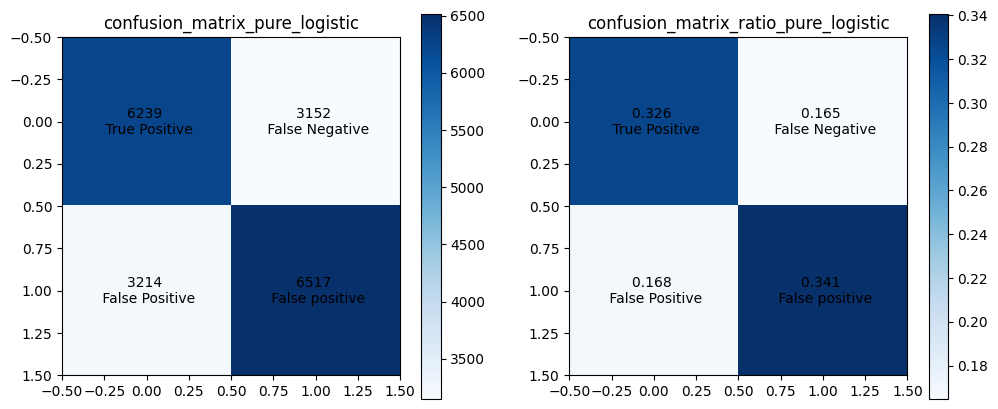

Penalized logistic regression: OK 



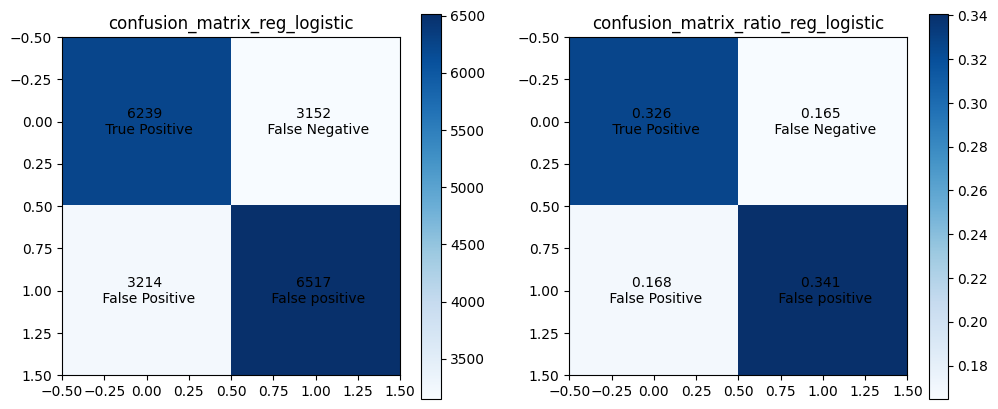

Pure logistic regression SGD: OK 



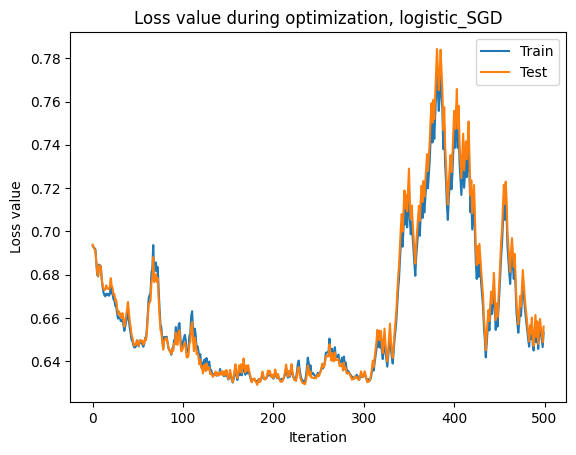

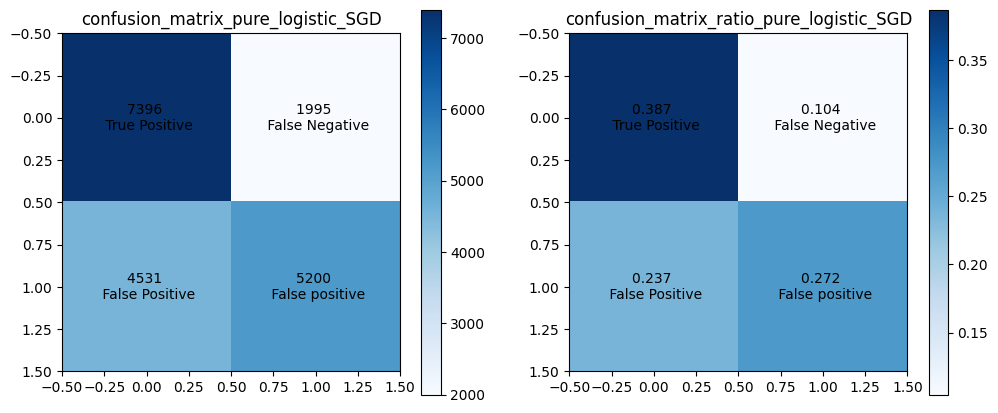

Penalized logistic regression SGD: OK 



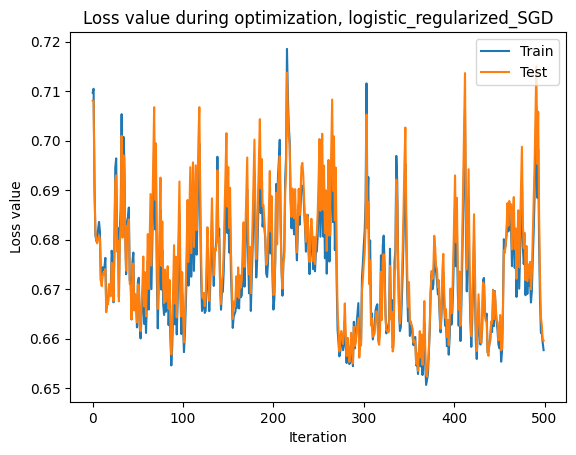

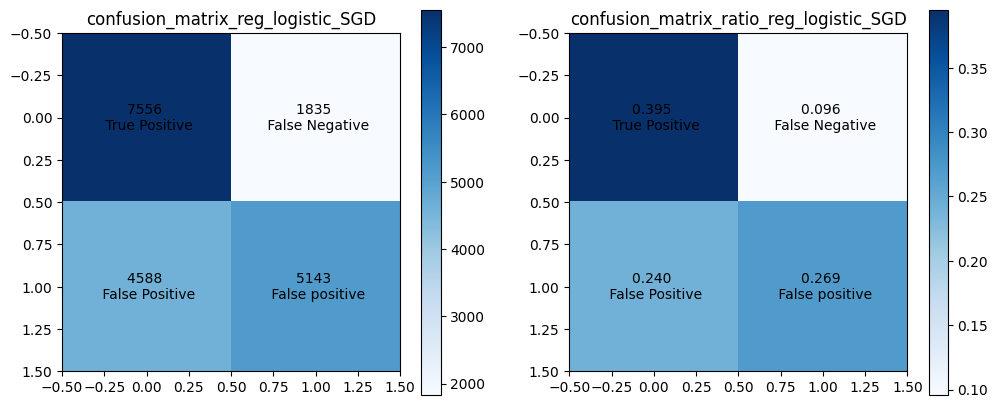

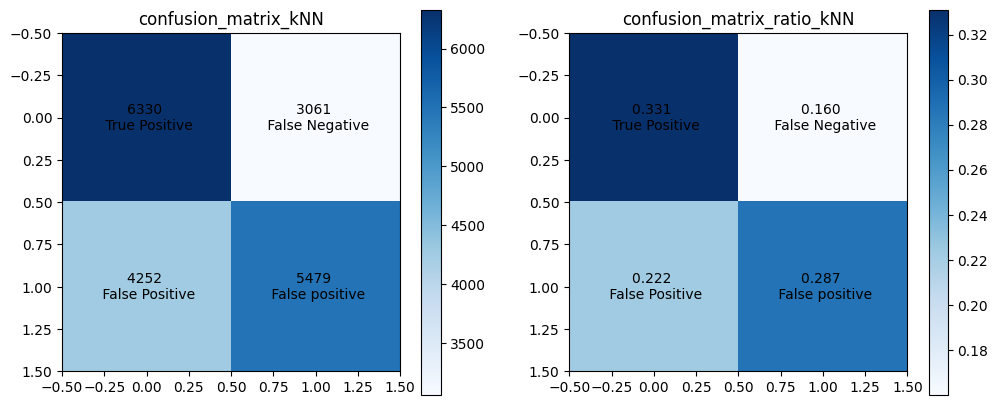

Final training accuracy = 70.84 %
Training time: 45.2 seconds 


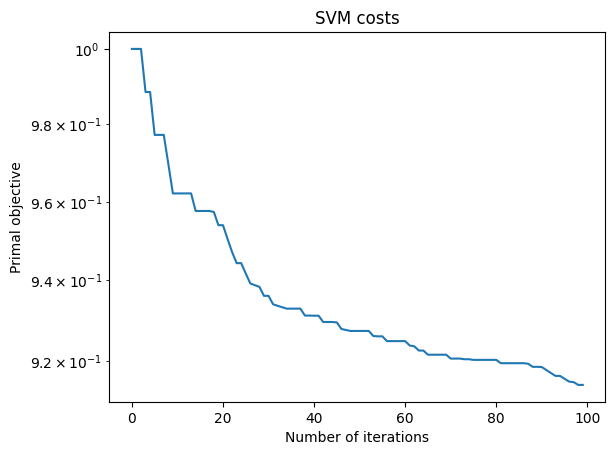

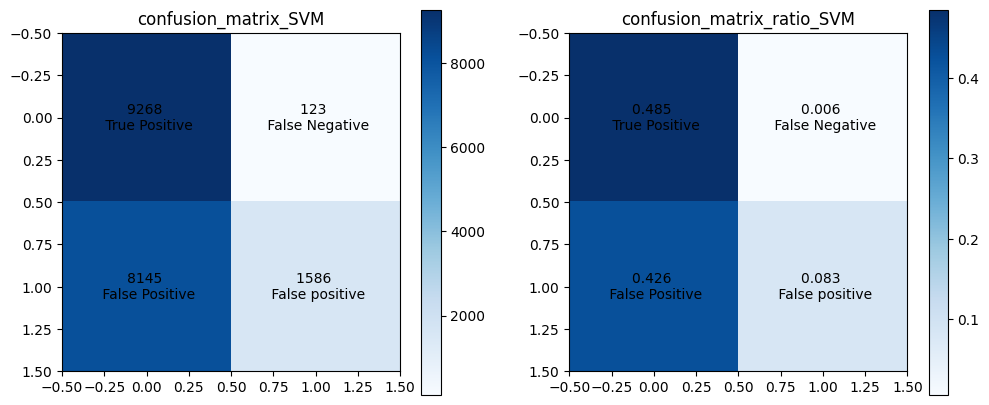

In [12]:
#### LOAD AND PREPROCESS ####

#Train
x_train, y_train, cont_params, cat_params, mask = load_data_train(DATA_DIR, imputation=imputation)
print("Load and preprocess train: OK \n")

#Test
x_test = load_data_test(DATA_DIR, cont_params, cat_params, mask, imputation=imputation)
print("Load and preprocess test: OK \n")



#### PREPROCESS FOR CLASSIFIERS ####

#Dtype (to change in case of being unable to allocate matrices with large type. Can be changed to np.float32)
dtype_array = np.float32

#Downsampling
if downsample == True :
    x_train, y_train = downsample_classes(x_train, y_train, random_state=0)
    print("Downsample: OK \n")

#Train/validation split
#Mask definition
rng = np.random.default_rng()
n = len(y_train)
ratio_mask = 33
mask = rng.random(n) >= ratio_mask / 100

#Train/validation split
x_tr = x_train[mask]
y_tr = y_train[mask]
x_te = x_train[~mask]
y_te = y_train[~mask]

#Add intercept
tx_tr = np.c_[np.ones((x_tr.shape[0], 1)), x_tr]
tx_tr = tx_tr.astype(dtype_array)
tx_te = np.c_[np.ones((x_te.shape[0], 1)), x_te]
tx_te = tx_te.astype(dtype_array)

# Initialize weights
initial_w = np.zeros(tx_tr.shape[1])



#### LOGISTIC REGRESSION ####
#Optimization params
max_iters = 500
gamma = 0.01
lambda_ = 0.5

#Pure logistic regression
if launch_pure_log == True :
    w_log, loss_log = logistic_regression(y_tr, tx_tr, initial_w, max_iters, gamma)
    print("Pure logistic regression: OK \n")

    #Class choice
    logistic_mask_log = sigmoid(tx_te @ w_log) >= 0.5
    y_te_pred_log = np.zeros((np.shape(tx_te)[0],1))
    y_te_pred_log[logistic_mask_log] = 1

    #Confusion matrix display
    confusion_matrix_log, confusion_matrix_ratio_log = confusion_matrix_custom(y_te, y_te_pred_log)
    display_confusion_matrix(confusion_matrix_log, confusion_matrix_ratio_log, "pure_logistic")


#Penalized logistic regression
if launch_reg_log == True :
    w_log_reg, loss_log_reg = reg_logistic_regression(y_tr, tx_tr, lambda_, initial_w, max_iters, gamma)
    print("Penalized logistic regression: OK \n")

    #Class choice
    logistic_mask_log_reg = sigmoid(tx_te @ w_log_reg) >= 0.5
    y_te_pred_log_reg = np.zeros((np.shape(tx_te)[0],1))
    y_te_pred_log_reg[logistic_mask_log_reg] = 1

    #Confusion matrix display
    confusion_matrix_log_reg, confusion_matrix_ratio_log_reg = confusion_matrix_custom(y_te, y_te_pred_log_reg)
    display_confusion_matrix(confusion_matrix_log_reg, confusion_matrix_ratio_log, "reg_logistic")



#### LOGISTIC REGRESSION SGD ####

#Pure logistic regression sgd
if launch_pure_log_sgd == True :
    #Optimization params
    max_iters = 500
    gamma = 2500
    w_log_sgd, losses_train_log_sgd, losses_test_log_sgd = logistic_regression_sgd(y_tr, tx_tr, y_te, tx_te, initial_w, max_iters, gamma)
    print("Pure logistic regression SGD: OK \n")

    #Losses display
    display_losses(losses_train_log_sgd, losses_test_log_sgd, "logistic_SGD")

    #Class choice
    logistic_mask_log_sgd = sigmoid(tx_te @ w_log_sgd) >= 0.5
    y_te_pred_log_sgd = np.zeros((np.shape(tx_te)[0],1))
    y_te_pred_log_sgd[logistic_mask_log_sgd] = 1

    #Display
    confusion_matrix_log_sgd, confusion_matrix_ratio_log_sgd = confusion_matrix_custom(y_te, y_te_pred_log_sgd)
    display_confusion_matrix(confusion_matrix_log_sgd, confusion_matrix_ratio_log_sgd, "pure_logistic_SGD")

#Penalized logistic regression sgd
if launch_reg_log_sgd == True :
    #Optimization params
    max_iters = 500
    gamma = 5000
    lambda_ = 0.000005
    w_log_reg_sgd, losses_train_log_reg_sgd, losses_test_log_reg_sgd = reg_logistic_regression_sgd(y_tr, tx_tr, y_te, tx_te, lambda_, initial_w, max_iters, gamma)
    print("Penalized logistic regression SGD: OK \n")

    #Losses display
    display_losses(losses_train_log_reg_sgd, losses_test_log_reg_sgd, "logistic_regularized_SGD")

    #Class choice
    logistic_mask_log_reg_sgd = sigmoid(tx_te @ w_log_reg_sgd) >= 0.5
    y_te_pred_log_reg_sgd = np.zeros((np.shape(tx_te)[0],1))
    y_te_pred_log_reg_sgd[logistic_mask_log_reg_sgd] = 1

    #Confusion matrix display
    confusion_matrix_log_reg_sgd, confusion_matrix_ratio_log_reg_sgd = confusion_matrix_custom(y_te, y_te_pred_log_reg_sgd)
    display_confusion_matrix(confusion_matrix_log_reg_sgd, confusion_matrix_ratio_log_reg_sgd, "reg_logistic_SGD")


#### kNN ####
if launch_kNN == True :
    #Prediction
    y_te_pred_kNN = kNN_custom_vectorized(x_tr, y_tr, x_te, 1)

    #Confusion matrix
    confusion_matrix_kNN, confusion_matrix_ratio_kNN = confusion_matrix_custom(y_te, y_te_pred_kNN)
    display_confusion_matrix(confusion_matrix_kNN, confusion_matrix_ratio_kNN, "kNN")


#### SVM ####
if launch_SVM == True :
    #SVM params
    max_iter = 100
    gamma = 0.1
    lambda_ = 0.01

    #SVM training
    w_SVM, costs = sgd_for_svm_demo(y_tr, x_tr, max_iter, gamma, lambda_)

    #Display cost
    plt.figure()
    plt.title("SVM costs")
    plt.plot(costs)
    plt.xlabel("Number of iterations")
    plt.ylabel("Primal objective")
    plt.yscale("log")
    plt.savefig(f"image/losses_SVM.png", dpi=300)
    plt.show()

    #Prediction
    y_te_pred_SVM = np.sign(x_te @ w_SVM)

    #Confusion matrix
    confusion_matrix_SVM, confusion_matrix_ratio_SVM = confusion_matrix_custom(y_te, y_te_pred_SVM)
    display_confusion_matrix(confusion_matrix_SVM, confusion_matrix_ratio_SVM, "SVM")

# 2-Predictions

In [32]:
#Reference x_test for indices
x_test_ref = np.genfromtxt(
    "x_test.csv",
    delimiter=",",
    skip_header=1
)
indices_array = x_test_ref[:,0].reshape(-1, 1)
print("Reference: OK")

Reference: OK


In [42]:
#Intercept
tx_test = np.c_[np.ones((x_test.shape[0], 1)), x_test]
tx_test = tx_test.astype(dtype_array)

#Pure logistic regression
if launch_pure_log == True :

    #Class choice
    logistic_mask_log = sigmoid(tx_test @ w_log) >= 0.5
    y_test_pred_log = - np.ones((np.shape(tx_test)[0],1))
    y_test_pred_log[logistic_mask_log] = 1

    #Prediction with indices
    y_submission_pred_log = np.hstack([indices_array, y_test_pred_log])

    #Save prediction
    np.savetxt(
        "predictions/y_test_pred_log.csv",
        y_submission_pred_log,
        delimiter=",",
        header="Id, Prediction",
        comments="",
        fmt="%d"
    )

#Penalized logistic regression
if launch_reg_log == True :

    #Class choice
    logistic_mask_log_reg = sigmoid(tx_test @ w_log_reg) >= 0.5
    y_test_pred_log_reg = - np.ones((np.shape(tx_test)[0],1))
    y_test_pred_log_reg[logistic_mask_log_reg] = 1

    #Prediction with indices
    y_submission_pred_log_reg = np.hstack([indices_array, y_test_pred_log_reg])

    #Save prediction
    np.savetxt(
        "predictions/y_test_pred_log_reg.csv",
        y_submission_pred_log_reg,
        delimiter=",",
        header="Id, Prediction",
        comments="",
        fmt="%d"
    )

if launch_pure_log_sgd == True :

    #Class choice
    logistic_mask_log_sgd = sigmoid(tx_test @ w_log_sgd) >= 0.5
    y_test_pred_log_sgd = - np.ones((np.shape(tx_test)[0],1))
    y_test_pred_log_sgd[logistic_mask_log_sgd] = 1

    #Prediction with indices
    y_submission_pred_log_sgd = np.hstack([indices_array, y_test_pred_log_sgd])

    #Save prediction
    np.savetxt(
        "predictions/y_test_pred_log_sgd.csv",
        y_submission_pred_log_sgd,
        delimiter=",",
        header="Id, Prediction",
        comments="",
        fmt="%d"
    )

#Penalized logistic regression sgd
if launch_reg_log_sgd == True :

    #Class choice
    logistic_mask_log_reg_sgd = sigmoid(tx_test @ w_log_reg_sgd) >= 0.5
    y_test_pred_log_reg_sgd = - np.ones((np.shape(tx_test)[0],1))
    y_test_pred_log_reg_sgd[logistic_mask_log_reg_sgd] = 1

    #Prediction with indices
    y_submission_pred_log_reg_sgd = np.hstack([indices_array, y_test_pred_log_reg_sgd])

    #Save prediction
    np.savetxt(
        "predictions/y_test_pred_log_reg_sgd.csv",
        y_submission_pred_log_reg_sgd,
        delimiter=",",
        header="Id, Prediction",
        comments="",
        fmt="%d"
    )

#SVM
if launch_SVM == True :
    #Prediction
    y_test_pred_SVM = np.sign(x_test @ w_SVM).reshape(-1,1)*2 - 1

    #Prediction with indices
    y_submission_pred_SVM = np.hstack([indices_array, y_test_pred_SVM])

    #Save prediction
    np.savetxt(
        "predictions/y_test_pred_SVM.csv",
        y_submission_pred_SVM,
        delimiter=",",
        header="Id, Prediction",
        comments="",
        fmt="%d"
    )

In [46]:
#kNN
if launch_kNN == True :
    #Prediction
    y_test_pred_kNN = kNN_custom_vectorized(x_tr, y_tr, x_test, 1)*2 - 1

    #Prediction with indices
    y_submission_pred_kNN = np.hstack([indices_array, y_test_pred_kNN])

    #Save prediction
    np.savetxt(
        "predictions/y_test_pred_kNN.csv",
        y_submission_pred_kNN,
        delimiter=",",
        header="Id, Prediction",
        comments="",
        fmt="%d"
    )